# 03. Regression Analysis

The outcome is the natural log of the asking price. For a coefficient β, `100 × (exp(β) − 1)` gives the estimated percentage difference in asking price for a one-unit increase in that variable, holding the other model variables fixed.

| Model | Formula | Comparison |
| --- | --- | --- |
| M1 | log_price ~ mileage_k | Total mileage alone |
| M2 | log_price ~ age | Vehicle age alone |
| M3 | log_price ~ mileage_k + age | Total mileage and age |
| **M4** | **log_price ~ mileage_k + age + C(brand)** | **Same brand and total mileage** |
| **M5** | **log_price ~ annual_mileage_k + age + C(brand)** | **Same brand and estimated annual mileage** |
| M6 | log_price ~ annual_mileage_k + age + C(model) + C(transmission) + C(fuelType) + engineSize | Additional vehicle characteristics |

Confidence intervals use HC3 heteroskedasticity-robust standard errors.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from features import load_raw, clean, pct_effect, PROCESSED_DIR, ROOT
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
df = pd.read_csv(PROCESSED_DIR / "cars_clean.csv")
formulas = {
    "M1": "log_price ~ mileage_k",
    "M2": "log_price ~ age",
    "M3": "log_price ~ mileage_k + age",
    "M4": "log_price ~ mileage_k + age + C(brand)",
    "M5": "log_price ~ annual_mileage_k + age + C(brand)",
    "M6": "log_price ~ annual_mileage_k + age + C(model) + C(transmission) + C(fuelType) + engineSize",
}
models = {k: smf.ols(f, data=df).fit(cov_type="HC3") for k, f in formulas.items()}

In [3]:
rows = []
for name, m in models.items():
    r = {"model": name, "R2": m.rsquared, "N": int(m.nobs)}
    for v in ["mileage_k", "annual_mileage_k", "age"]:
        if v in m.params:
            r[v] = f"{m.params[v]:.4f} ({m.bse[v]:.4f})"
            r[v + " %"] = round(pct_effect(m.params[v]), 2)
    rows.append(r)
summary = pd.DataFrame(rows).set_index("model")
summary.to_csv(ROOT / "figures" / "regression_summary.csv")
summary

,R2,N,mileage_k,mileage_k %,age,age %,annual_mileage_k,annual_mileage_k %
model,,,,,,,,
M1,0.235,96255,-0.0124 (0.0001),-1.230,NaN,NaN,NaN,NaN
M2,0.361,96255,NaN,NaN,-0.1533 (0.0009),-14.210,NaN,NaN
M3,0.363,96255,-0.0020 (0.0001),-0.200,-0.1386 (0.0014),-12.940,NaN,NaN
M4,0.676,96255,-0.0038 (0.0001),-0.380,-0.1202 (0.0010),-11.320,NaN,NaN
M5,0.674,96255,NaN,NaN,-0.1456 (0.0007),-13.550,-0.0106 (0.0002),-1.060
M6,0.938,96255,NaN,NaN,-0.1354 (0.0004),-12.670,-0.0154 (0.0001),-1.530


Numbers in parentheses are HC3 standard errors. The percentage columns express estimated differences in asking price per year of age or per 1,000 miles in the corresponding mileage measure. R² is calculated on the estimation sample.

In [4]:
print(models["M5"].summary().tables[1].as_text()[:2500])

                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 10.4203      0.004   2955.281      0.000      10.413      10.427
C(brand)[T.BMW]           -0.0082      0.004     -2.073      0.038      -0.016      -0.000
C(brand)[T.Ford]          -0.5424      0.003   -158.482      0.000      -0.549      -0.536
C(brand)[T.Hyundai]       -0.5698      0.006   -100.993      0.000      -0.581      -0.559
C(brand)[T.Mercedes]       0.0614      0.004     16.662      0.000       0.054       0.069
C(brand)[T.Skoda]         -0.5060      0.005   -101.148      0.000      -0.516      -0.496
C(brand)[T.Toyota]        -0.5471      0.006    -96.211      0.000      -0.558      -0.536
C(brand)[T.Vauxhall]      -0.7058      0.003   -206.592      0.000      -0.713      -0.699
C(brand)[T.Volkswagen]    -0.3134      0.004    -80.655      0.000      -0.321      -0.306

## Multicollinearity diagnostic

The variance inflation factor (VIF) measures the overlap between predictors. Here VIF is calculated for the age and mileage pairs alone. It is 2.31 for age and total mileage and 1.02 for age and estimated annual mileage. Each pair represents a different comparison in the price models.

In [5]:
def vif_table(cols):
    X = df[cols].assign(const=1.0).values
    return pd.Series([variance_inflation_factor(X, i) for i in range(len(cols))], index=cols)

pd.DataFrame({"total mileage + age (M3)": vif_table(["mileage_k", "age"]).values,
              "annual mileage + age (M5)": vif_table(["annual_mileage_k", "age"]).values},
             index=["mileage variable", "age"])

,total mileage + age (M3),annual mileage + age (M5)
mileage variable,2.305,1.020
age,2.305,1.020


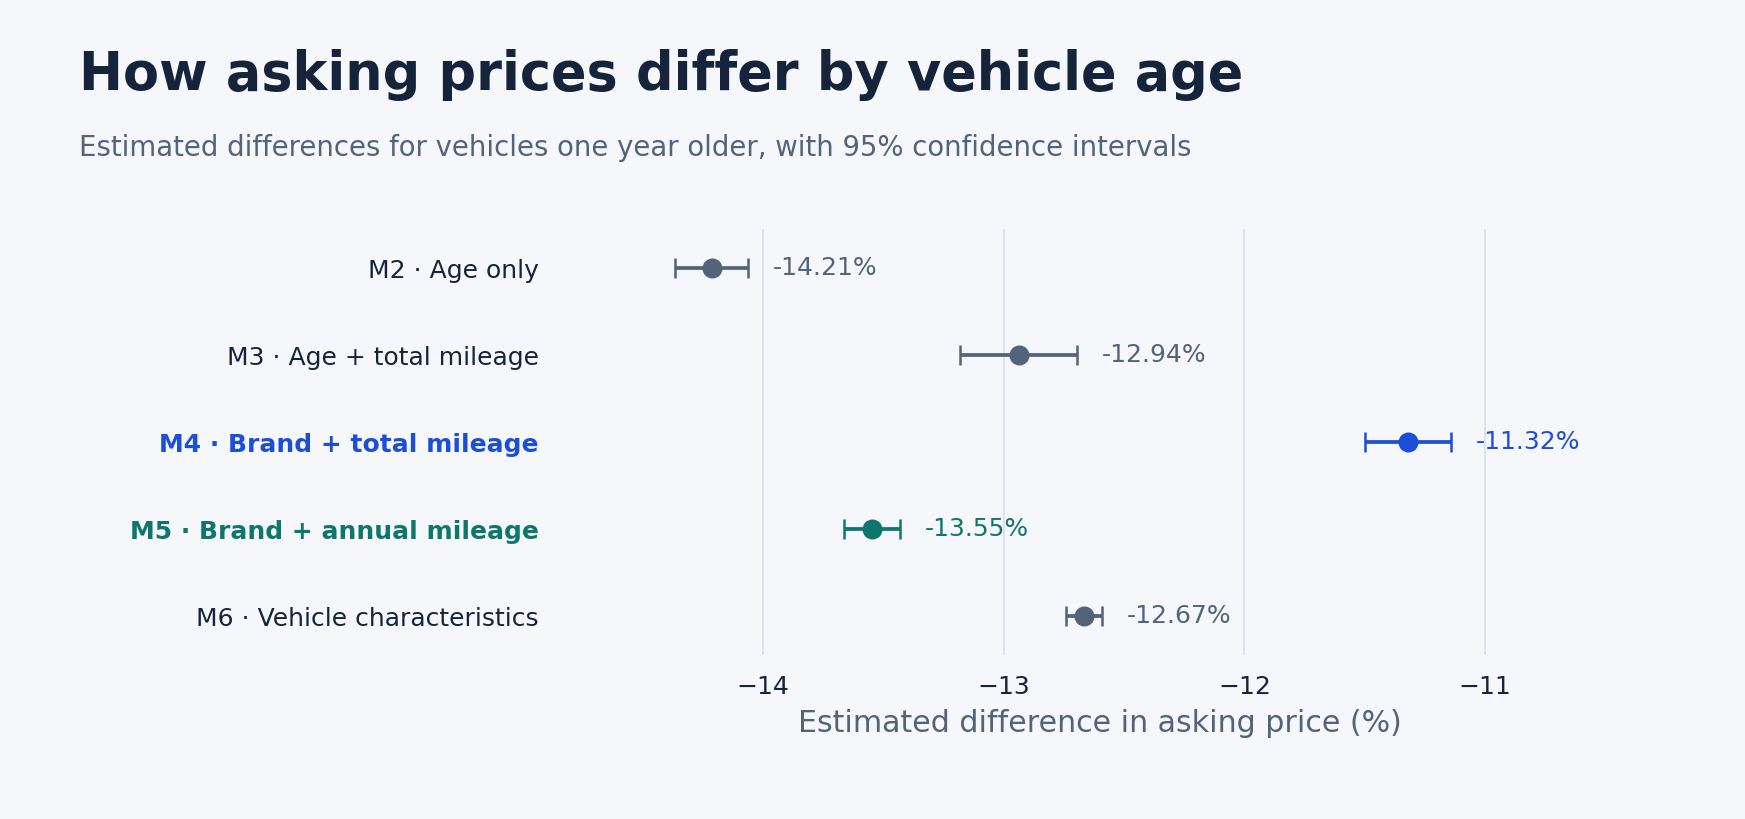

In [6]:
labels = {
    "M2": "M2 · Age only",
    "M3": "M3 · Age + total mileage",
    "M4": "M4 · Brand + total mileage",
    "M5": "M5 · Brand + annual mileage",
    "M6": "M6 · Vehicle characteristics",
}
highlights = {"M4": "#1D4ED8", "M5": "#0F766E"}
background = "#F5F7FB"
ink = "#15243A"
muted = "#52637A"
fig, ax = plt.subplots(figsize=(9.7, 4.55), facecolor=background)
fig.subplots_adjust(left=0.32, right=0.94, top=0.72, bottom=0.20)
ax.set_facecolor(background)

for y, name in enumerate(labels):
    m = models[name]
    estimate = pct_effect(m.params["age"])
    low, high = pct_effect(m.conf_int().loc["age"])
    color = highlights.get(name, muted)
    ax.errorbar(
        estimate, y, xerr=[[estimate - low], [high - estimate]],
        fmt="o", markersize=7, linewidth=1.5, capsize=4, color=color, zorder=3,
    )
    ax.annotate(
        f"{estimate:.2f}%", (high, y), xytext=(10, 0), textcoords="offset points",
        va="center", color=color, fontsize=10,
    )

ax.set(xlim=(-14.85, -10.35), ylim=(4.45, -0.45), xlabel="Estimated difference in asking price (%)")
ax.set_xticks([-14, -13, -12, -11])
ax.set_yticks(range(len(labels)), labels.values())
ax.tick_params(axis="both", length=0, pad=8, labelcolor=ink, labelsize=10)
ax.xaxis.label.set_color(muted)
for tick, name in zip(ax.get_yticklabels(), labels):
    if name in highlights:
        tick.set_color(highlights[name])
        tick.set_fontweight("bold")
ax.grid(False)
ax.grid(axis="x", color="#DCE3EE", linewidth=0.8)
for spine in ax.spines.values():
    spine.set_visible(False)

fig.text(0.045, 0.89, "How asking prices differ by vehicle age", fontsize=21, weight="bold", color=ink)
fig.text(0.045, 0.81, "Estimated differences for vehicles one year older, with 95% confidence intervals", fontsize=11, color=muted)
fig.savefig(FIG_DIR / "04_age_effect_by_model.png", dpi=180)
plt.show()
plt.close(fig)

## Age and asking price by brand

The M5 age and estimated annual mileage terms are fitted separately for each brand. The estimates indicate how the association varies across brands.

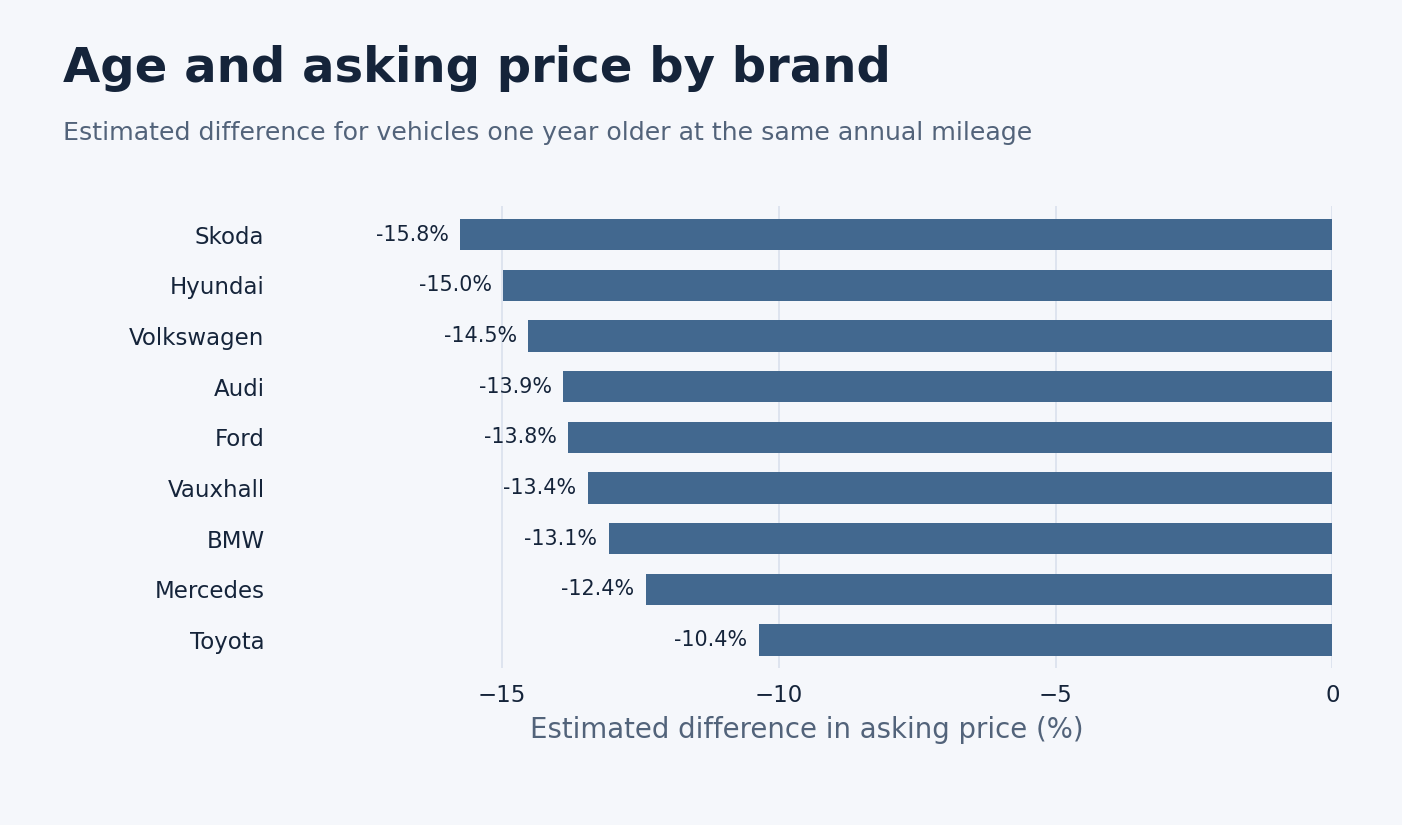

brand
Skoda        -15.800
Hyundai      -15.000
Volkswagen   -14.500
Audi         -13.900
Ford         -13.800
Vauxhall     -13.400
BMW          -13.100
Mercedes     -12.400
Toyota       -10.400
dtype: float64

In [7]:
by_brand = (
    df.groupby("brand")[["log_price", "annual_mileage_k", "age"]]
    .apply(lambda d: pct_effect(smf.ols("log_price ~ annual_mileage_k + age", d).fit().params["age"]))
    .sort_values()
)
fig, ax = plt.subplots(figsize=(8.5, 5), facecolor=background)
fig.subplots_adjust(left=0.20, right=0.95, top=0.75, bottom=0.19)
ax.set_facecolor(background)
by_brand.plot.barh(ax=ax, width=0.62, color="#42688F", edgecolor="none")
ax.invert_yaxis()
ax.set(xlim=(-19, 0), xlabel="Estimated difference in asking price (%)", ylabel="")
ax.set_xticks([-15, -10, -5, 0])
ax.tick_params(axis="both", length=0, pad=7, labelcolor=ink, labelsize=10)
ax.xaxis.label.set_color(muted)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=5, fontsize=9, color=ink)
ax.grid(False)
ax.grid(axis="x", color="#DCE3EE", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_visible(False)

fig.text(0.045, 0.90, "Age and asking price by brand", fontsize=21, weight="bold", color=ink)
fig.text(0.045, 0.83, "Estimated difference for vehicles one year older at the same annual mileage", fontsize=11, color=muted)
fig.savefig(FIG_DIR / "05_age_effect_by_brand.png", dpi=165)
plt.show()
plt.close(fig)
by_brand.round(1)

## Sensitivity to the age range

Refit M5 on two subsets of the cleaned data. The first excludes vehicles assigned age zero, whose estimated annual mileage uses a denominator of one. The second excludes both age-zero and age-one vehicles.

In [8]:
age_samples = {
    "All listings": models["M5"],
    "Age ≥ 1 year": smf.ols(formulas["M5"], data=df.loc[df["age"] >= 1]).fit(cov_type="HC3"),
    "Age ≥ 2 years": smf.ols(formulas["M5"], data=df.loc[df["age"] >= 2]).fit(cov_type="HC3"),
}
sensitivity_rows = []
for label, m in age_samples.items():
    low, high = pct_effect(m.conf_int().loc["age"])
    sensitivity_rows.append({
        "Sample": label,
        "Listings": int(m.nobs),
        "Age difference (%)": pct_effect(m.params["age"]),
        "95% CI lower (%)": low,
        "95% CI upper (%)": high,
    })
sensitivity = pd.DataFrame(sensitivity_rows).set_index("Sample").round(2)
sensitivity

,Listings,Age difference (%),95% CI lower (%),95% CI upper (%)
Sample,,,,
All listings,96255,-13.550,-13.660,-13.430
Age ≥ 1 year,92343,-13.580,-13.710,-13.460
Age ≥ 2 years,66570,-12.250,-12.420,-12.080


## Interpretation

- **M1 to M4.** A further 1,000 total miles is associated with a 1.23% lower asking price in M1, 0.20% lower after accounting for age in M3, and 0.38% lower after also accounting for brand in M4.
- **M4 and M5.** Within the same brand, the estimated price difference for vehicles one year older is −11.32% at the same total mileage and −13.55% at the same estimated annual mileage. From age one onward, the older vehicle in the second comparison has more accumulated miles.
- **Sensitivity.** The M5 estimate is similar after excluding vehicles assigned age zero and smaller in magnitude for vehicles aged two or older. M6 estimates a −12.67% difference with vehicle characteristics included.

These are conditional associations among listings. The data do not follow individual cars over time or record their final transaction prices. Condition, accident history, options, and location are unavailable. About 98% of the cleaned sample is zero to seven years old.